# Safe: v3 against every alternative we tested

One notebook that puts side by side the current strategy (**v3**), the original one (**v1**), four simple benchmarks and **eleven alternatives**, one for each idea we tested (from the literature and from the feedback received). Same data, same costs, same period.

**How the winner is chosen (fixed before looking at the results).** Safe is meant for a low-drawdown investor, so:
1. a strategy must never lose more than **12%** from a peak (monthly data);
2. among those, the winner is the one with the **highest Sharpe ratio in its worse half** of the sample (2008-2016 or 2017-2026). A good strategy must work in both periods, not just on average;
3. an alternative replaces v3 only if it beats it by at least **0.05** on that measure. Smaller gaps are noise, and then the strategy already running stays.

**Glossary.** *Sharpe*: return above the T-bill per unit of risk. *SE*: its standard error (how uncertain it is). *Max drawdown*: worst loss from a peak. *Turnover*: how much of the portfolio is traded per year.

In [10]:
import os
import sys
import warnings
from dataclasses import replace

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests

sys.path.append(os.path.join("..", "src"))
from data import download_prices, prepare_monthly
from strategies import (trend_momentum_signal, correlation_filter, momentum_weights,
                        inverse_vol_weights, safe_v3_weights, _apply_cap, SAFE_EQUITY)
from backtest import daily_path, max_drawdown
import benchmarks as bm

warnings.filterwarnings("ignore")
DATA_DIR = os.path.join("..", "data")
UNIVERSE = ["SPY", "QQQ", "IWM", "VWO", "GLD", "SHV", "IEF", "TLT", "TIP", "LQD"]
RISKY = [t for t in UNIVERSE if t != "SHV"]
BONDS = ["IEF", "TLT", "TIP"]
TICKER_COSTS = {"SPY": 0.0002, "QQQ": 0.0003, "SHV": 0.0001, "IEF": 0.0002, "TLT": 0.0003,
                "IWM": 0.0004, "GLD": 0.0004, "LQD": 0.0004, "VWO": 0.0008, "TIP": 0.0003}
SPLIT = "2016-12-31"
MAX_DD_LIMIT = -0.12
TARGET_VOL = 0.075
MIN_GAIN = 0.05

## 1. Data

In [11]:
prices = download_prices(UNIVERSE, years=20, cache_path=os.path.join(DATA_DIR, "prices_safe.csv"))
md = prepare_monthly(prices, sma_window=200)
R, Rd, dates = md.returns, md.daily_returns, md.prices.index
ff = bm.load_fama_french(os.path.join(DATA_DIR, "ff_factors_monthly.csv"))
rf = ff["RF"].reindex(R.index).ffill().fillna(0.0)          # 1-month T-bill
excess = R[RISKY].sub(rf, axis=0)

def fred(series):
    # FRED series: saved copy in data/fred, otherwise the FRED API (key in ibkr_keys.env: FRED_API_KEY=...)
    path = os.path.join(DATA_DIR, "fred", f"{series}.csv")
    if not os.path.exists(path):
        key = ""
        keys_file = os.path.join("..", "ibkr_keys.env")
        if os.path.exists(keys_file):
            for line in open(keys_file, encoding="utf-8"):
                if line.strip().startswith("FRED_API_KEY="):
                    key = line.split("=", 1)[1].strip()
        r = requests.get("https://api.stlouisfed.org/fred/series/observations", timeout=60,
                         params={"series_id": series, "api_key": key, "file_type": "json"})
        obs = r.json()["observations"]
        os.makedirs(os.path.dirname(path), exist_ok=True)
        pd.DataFrame({"date": [o["date"] for o in obs], series: [o["value"] for o in obs]}).to_csv(path, index=False)
    df = pd.read_csv(path)
    s = pd.to_numeric(df.iloc[:, 1], errors="coerce")
    s.index = pd.to_datetime(df.iloc[:, 0])
    return s.dropna()

# credit spread Baa - Aaa (monthly, used one month later because of the publication delay)
dfy = (fred("BAA") - fred("AAA")).resample("ME").last().shift(1)
print(f"\nCredit spread Baa-Aaa: {dfy.dropna().index[0]:%Y-%m} -> {dfy.dropna().index[-1]:%Y-%m}")

Downloaded 2006-10-27 -> 2026-10-22. First valid date per ETF:
  SPY   2006-10-27
  QQQ   2006-10-27
  IWM   2006-10-27
  VWO   2006-10-27
  GLD   2006-10-27
  SHV   2007-01-11
  IEF   2006-10-27
  TLT   2006-10-27
  TIP   2006-10-27
  LQD   2006-10-27
Fama-French: 1963-07 -> 2026-08, downloaded

Credit spread Baa-Aaa: 1919-02 -> 2026-09


## 2. Helper functions
All weights are decided at the end of a month and earn the returns of the next month. Costs are charged on every trade.

In [12]:
def net_returns(W):
    # monthly returns after costs, and two-way turnover
    first = W[W.sum(axis=1) > 0].index[0]
    gross = (W.shift(1) * R).sum(axis=1).loc[first:]
    trades = W.diff().abs()
    trades.loc[first] = W.loc[first]
    cost = (trades * pd.Series(TICKER_COSTS)).sum(axis=1).shift(1).fillna(0).loc[first:]
    return gross - cost, trades.sum(axis=1).loc[first:]

def drawdown(r):
    nav = pd.concat([pd.Series([1.0]), (1 + r.reset_index(drop=True)).cumprod()])
    return (nav / nav.cummax() - 1).min()

def sharpe(r):
    ex = r - rf.reindex(r.index)
    return ex.mean() / ex.std() * np.sqrt(12)

def sharpe_se(r):
    # standard error of the Sharpe ratio (Lo 2002, adjusted for skewness and fat tails)
    ex = r - rf.reindex(r.index)
    s, T = ex.mean() / ex.std(), len(ex)
    var = (1 + 0.5 * s**2 - ex.skew() * s + ex.kurt() / 4 * s**2) / T
    return np.sqrt(var * 12)

def p_value(a, b):
    # is the Sharpe difference between two strategies bigger than noise? (Jobson-Korkie / Memmel test)
    import math
    d = pd.concat([a - rf.reindex(a.index), b - rf.reindex(b.index)], axis=1).dropna()
    x, y = d.iloc[:, 0], d.iloc[:, 1]
    sa, sb, rho, T = x.mean() / x.std(), y.mean() / y.std(), x.corr(y), len(d)
    var = (2 - 2 * rho + 0.5 * (sa**2 + sb**2 - 2 * sa * sb * rho**2)) / T
    return math.erfc(abs((sa - sb) / math.sqrt(var)) / math.sqrt(2)) if var > 0 else np.nan

def cap_equity(W, cap):
    # total equity (SPY, QQQ, IWM, VWO) <= cap; the excess goes to T-bills
    W = W.copy()
    cap = pd.Series(cap, index=W.index)
    eq = W[SAFE_EQUITY].sum(axis=1)
    k = (cap / eq).where(eq > cap, 1.0).fillna(1.0)
    W["SHV"] += (W[SAFE_EQUITY].mul(1 - k, axis=0)).sum(axis=1)
    W[SAFE_EQUITY] = W[SAFE_EQUITY].mul(k, axis=0)
    return W

vol60 = Rd.rolling(60, min_periods=60).std().resample("ME").last() * np.sqrt(252)
cov60 = {d: Rd.loc[:d].tail(60).cov() * 252 for d in dates if len(Rd.loc[:d]) >= 60}
cov126 = {d: Rd.loc[:d, RISKY].tail(126).cov() * 252 for d in dates if len(Rd.loc[:d]) >= 126}

def vol_target_and_floor(W, target=None, floor=None, cov=cov126):
    # (a) scale risky weights to the target volatility, never above 100% invested;
    # (b) single ETF <= 30%, equity <= 60%; (c) bonds IEF+TLT+TIP >= floor. Rest in T-bills.
    out = W.copy()
    for d in W.index:
        w = W.loc[d, RISKY].copy()
        if w.sum() <= 0:
            continue
        if target is not None and d in cov:
            v = np.sqrt(w.values @ cov[d].loc[RISKY, RISKY].values @ w.values)
            if v > 0:
                w *= min(target / v, 1 / w.sum())
        w = w.clip(upper=0.30)
        if w[SAFE_EQUITY].sum() > 0.60:
            w[SAFE_EQUITY] *= 0.60 / w[SAFE_EQUITY].sum()
        if floor is not None and w[BONDS].sum() < floor:
            need = floor - w[BONDS].sum()
            iv = 1 / vol60.loc[d, BONDS]
            spare = 1 - w.sum()
            if need > spare:                                   # make room by scaling the others down
                others = [c for c in RISKY if c not in BONDS]
                w[others] *= max(0.0, 1 - (need - spare) / w[others].sum())
            w[BONDS] += need * iv / iv.sum()
        out.loc[d, RISKY] = w.values
        out.loc[d, "SHV"] = max(0.0, 1 - w.sum())
    return out

def erc_weights(cov_by_month, winners_by_month):
    # equal risk contribution: each selected ETF contributes the same share of portfolio risk
    W = pd.DataFrame(0.0, index=dates, columns=UNIVERSE)
    for d in dates:
        win = winners_by_month.loc[d][winners_by_month.loc[d] == 1].index.tolist()
        if not win or d not in cov_by_month:
            W.loc[d, "SHV"] = 1.0
            continue
        C = cov_by_month[d].loc[win, win].values
        w = pd.Series(bm._erc_weights(C), index=win)
        w = _apply_cap(w, 0.25, 10)
        W.loc[d, win] = w.values
        W.loc[d, "SHV"] += 1 - W.loc[d].sum()
    return cap_equity(W, 0.60)
print("Helpers ready.")

Helpers ready.


## 2b. DCC correlations (only for RISK_PARITY_DCC)
Each December the model is estimated on past daily returns only (last 10 years), then used for the next 12 months. Step 1: a GARCH model for the volatility of each ETF. Step 2: a DCC model for how correlations move over time. Takes a few minutes.

In [13]:
from scipy.optimize import minimize

def garch_fit(x):
    x = x - x.mean(); v0 = x.var()
    def nll(p):
        om, al, be = p
        if om <= 0 or al < 0 or be < 0 or al + be >= 0.999:
            return 1e10
        h = np.empty_like(x); h[0] = v0
        for t in range(1, len(x)):
            h[t] = om + al * x[t - 1] ** 2 + be * h[t - 1]
        return 0.5 * np.sum(np.log(h) + x ** 2 / h)
    return minimize(nll, [v0 * 0.05, 0.08, 0.90], method="Nelder-Mead",
                    options={"maxiter": 400, "xatol": 1e-6, "fatol": 1e-4}).x

def garch_filter(x, p):
    om, al, be = p
    x = x - x.mean(); h = np.empty(len(x) + 1); h[0] = x.var()
    for t in range(1, len(x) + 1):
        h[t] = om + al * x[t - 1] ** 2 + be * h[t - 1]
    return h                                   # h[t]: variance forecast for day t

def dcc_fit(E):
    Qbar = np.cov(E.T)
    def nll(p):
        a, b = p
        if a < 0 or b < 0 or a + b >= 0.999:
            return 1e10
        Q, ll = Qbar.copy(), 0.0
        for t in range(1, len(E)):
            Q = (1 - a - b) * Qbar + a * np.outer(E[t - 1], E[t - 1]) + b * Q
            d = 1 / np.sqrt(np.diag(Q)); Rt = Q * np.outer(d, d)
            sign, logdet = np.linalg.slogdet(Rt)
            if sign <= 0:
                return 1e10
            ll += logdet + E[t] @ np.linalg.solve(Rt, E[t])
        return 0.5 * ll
    return minimize(nll, [0.02, 0.95], method="Nelder-Mead", options={"maxiter": 200}).x, Qbar

def dcc_cov(daily, assets, max_days=2520):
    Rr = daily[assets].dropna()
    out = {}
    for y in range(Rr.index[0].year + 4, dates[-1].year + 1):
        est = Rr.loc[:f"{y - 1}-12-31"].tail(max_days).values * 100
        pars = [garch_fit(est[:, j]) for j in range(len(assets))]
        H = np.column_stack([garch_filter(est[:, j], pars[j])[:-1] for j in range(len(assets))])
        (a, b), Qbar = dcc_fit((est - est.mean(0)) / np.sqrt(H))
        print(f"  DCC estimated with data to {y - 1}: a = {a:.3f}, b = {b:.3f}")
        blk = Rr.loc[:f"{y}-12-31"].tail(max_days + 260)
        full = blk.values * 100
        H = np.column_stack([garch_filter(full[:, j], pars[j]) for j in range(len(assets))])
        E = (full - full.mean(0)) / np.sqrt(H[:-1])
        Q = Qbar.copy(); Qs = [Q]
        for t in range(1, len(E) + 1):
            Q = (1 - a - b) * Qbar + a * np.outer(E[t - 1], E[t - 1]) + b * Q
            Qs.append(Q)
        me = blk.index + pd.offsets.MonthEnd(0)
        for i, d in enumerate(blk.index):
            if d.year != y or (i + 1 < len(blk) and me[i + 1] == me[i]):
                continue                                   # keep only the last day of each month
            dq = 1 / np.sqrt(np.diag(Qs[i + 1]))
            sd = np.sqrt(H[i + 1]) / 100
            out[me[i]] = pd.DataFrame(Qs[i + 1] * np.outer(dq, dq) * np.outer(sd, sd) * 252,
                                      index=assets, columns=assets)
    return out

dcc = dcc_cov(Rd, RISKY)
cov_dcc = {}
for d, C in cov60.items():                                 # T-bills and months before the first estimate: 60-day covariance
    C = C.copy()
    if d in dcc:
        C.loc[RISKY, RISKY] = dcc[d].values
    cov_dcc[d] = C
print(f"DCC covariance available for {len(dcc)} month ends.")

  DCC estimated with data to 2009: a = 0.022, b = 0.953
  DCC estimated with data to 2010: a = 0.027, b = 0.944
  DCC estimated with data to 2011: a = 0.028, b = 0.943
  DCC estimated with data to 2012: a = 0.027, b = 0.943
  DCC estimated with data to 2013: a = 0.026, b = 0.950
  DCC estimated with data to 2014: a = 0.024, b = 0.957
  DCC estimated with data to 2015: a = 0.023, b = 0.958
  DCC estimated with data to 2016: a = 0.022, b = 0.960
  DCC estimated with data to 2017: a = 0.021, b = 0.967
  DCC estimated with data to 2018: a = 0.021, b = 0.963
  DCC estimated with data to 2019: a = 0.023, b = 0.954
  DCC estimated with data to 2020: a = 0.023, b = 0.955
  DCC estimated with data to 2021: a = 0.022, b = 0.957
  DCC estimated with data to 2022: a = 0.023, b = 0.956
  DCC estimated with data to 2023: a = 0.024, b = 0.958
  DCC estimated with data to 2024: a = 0.024, b = 0.961
  DCC estimated with data to 2025: a = 0.025, b = 0.959
DCC covariance available for 202 month ends.


## 3. The strategies

| # | Name | Idea in one sentence | Where it comes from |
|---|---|---|---|
| | **V3** | Trend filter (200-day average + 3-month return), up to 5 ETFs, weights by inverse volatility, equity ≤ 60% | current version |
| | **V1** | Same selection, but weights by momentum and no equity limit | original version |
| 1 | **WALK_FORWARD** | v3, but every year the two parameters (average length, momentum months) are re-chosen using only past data | Goyal-Welch: out-of-sample |
| 2 | **TURNING_POINTS** | Keep 100% of an ETF if its 12-month and 2-month trends are both up, 50% if they disagree, 0% if both down | Goulding-Harvey-Mazzoleni |
| 3 | **DAILY_EXIT** | v3, but sell an ETF as soon as it closes below its 200-day average, without waiting for month end | Breaking Bad Trends |
| 4 | **BOND_FLOOR** | v3, but always hold at least 20% in Treasuries and TIPS | suggestion received |
| 5 | **RISK_PARITY_WEIGHTS** | v3 selection, but weights so that each ETF contributes the same risk (uses correlations) | brief: ERC |
| 6 | **RISK_PARITY_DCC** | Same as 5, but correlations estimated with a DCC-GARCH model (they react faster to crises) | brief: DCC |
| 7 | **CORR_HEDGE** | v3, but when stocks and bonds move in opposite directions (correlation below -0.2) move up to 15% of the idle cash into Treasuries | brief: stock-bond correlation |
| 8 | **CREDIT_FILTER** | v3, but equity ≤ 30% when the Baa-Aaa credit spread is high and rising | brief: dfy as risk filter |
| 9 | **VOL_TARGET** | v3, but less idle cash: scale the risky part to 7.5% volatility (no leverage) | Moreira-Muir |
| 10 | **MULTI_HORIZON_TREND** | Hold each ETF in proportion to how many of its 1, 3, 6, 12-month trends are up; weights by inverse volatility; 7.5% volatility target | Hurst-Ooi-Pedersen |
| 11 | **RISK_PARITY_TREND** | Risk-parity portfolio of all 9 ETFs × multi-horizon trend, 7.5% volatility target, at least 20% bonds | rebuilt architecture |

Benchmarks: **60/40** (60% S&P 500, 40% Treasuries), **Trend 1/N** (textbook trend-following: each ETF 1/9 if above its 10-month average), **Risk parity** (all 9 ETFs, equal risk), **S&P 500**.

In [14]:
W = {}
selected = correlation_filter(trend_momentum_signal(md), md.mom_3m, Rd, 5, 0.80)
W["V3"] = safe_v3_weights(md)
W["V1"] = momentum_weights(selected, md.mom_3m, 0.25, 0.40, 0.05)

# 1. WALK_FORWARD: each December pick the (SMA, momentum) pair with the best past Sharpe
grid = {}
for sma in [100, 150, 200, 250]:
    md_s = prepare_monthly(prices, sma_window=sma)
    for mom in [1, 3, 6, 12]:
        w = safe_v3_weights(replace(md_s, mom_3m=md_s.prices.pct_change(mom)))
        grid[(sma, mom)] = (w, net_returns(w)[0])
W_wf = pd.DataFrame(np.nan, index=dates, columns=W["V3"].columns)
choice = {}
decisions = [d for d in dates if d.month == 12 and d.year >= 2012]
for i, d in enumerate(decisions):
    start = W["V3"].drop(columns="SHV").sum(axis=1).gt(0).idxmax()
    best = max(grid, key=lambda k: sharpe(grid[k][1].loc[start:d]))
    choice[d.year + 1] = best
    end = decisions[i + 1] if i + 1 < len(decisions) else dates[-1] + pd.offsets.MonthEnd(1)
    rows = (dates >= d) & (dates < end)
    W_wf.loc[rows, :] = grid[best][0].loc[rows, W_wf.columns].values
W["WALK_FORWARD"] = W_wf.dropna()

# 2. TURNING_POINTS
slow = excess.rolling(12).mean()
fast = excess.rolling(2).mean()
exposure = pd.DataFrame(np.select([(slow >= 0) & (fast >= 0), (slow < 0) & (fast < 0)], [1.0, 0.0], 0.5),
                        index=excess.index, columns=RISKY).where(slow.notna(), 0.0)
signal = trend_momentum_signal(md).copy()
signal[RISKY] = exposure > 0
w = inverse_vol_weights(correlation_filter(signal, md.mom_3m, Rd, 5, 0.80), Rd, 0.25)
w[RISKY] = w[RISKY] * exposure
w["SHV"] = 1 - w[RISKY].sum(axis=1)
W["TURNING_POINTS"] = cap_equity(w, 0.60)

# 4. BOND_FLOOR, 9. VOL_TARGET
W["BOND_FLOOR"] = vol_target_and_floor(W["V3"], target=None, floor=0.20)
W["VOL_TARGET"] = vol_target_and_floor(W["V3"], target=TARGET_VOL)

# 5. RISK_PARITY_WEIGHTS
W["RISK_PARITY_WEIGHTS"] = erc_weights(cov60, selected)

W["RISK_PARITY_DCC"] = erc_weights(cov_dcc, selected)

# 7. CORR_HEDGE: one-year daily correlation SPY-IEF known at month end
corr_sb = Rd["SPY"].rolling(252, min_periods=200).corr(Rd["IEF"]).resample("ME").last().reindex(dates)
w = W["V3"].copy()
on = corr_sb < -0.2
move = np.minimum(0.15, w.loc[on, "SHV"])
w.loc[on, "IEF"] += move
w.loc[on, "SHV"] -= move
W["CORR_HEDGE"] = w

# 8. CREDIT_FILTER: spread above its own historical 80th percentile and higher than 3 months ago
high = dfy > dfy.expanding(60).quantile(0.80)      # only data known up to that month
rising = dfy.diff(3) > 0
stress = (high & rising).reindex(dates).fillna(False)
W["CREDIT_FILTER"] = cap_equity(W["V3"], np.where(stress, 0.30, 1.0))

# 10. MULTI_HORIZON_TREND and 11. RISK_PARITY_TREND
logex = np.log1p(excess)
trend_share = sum((logex.rolling(h).sum() > 0).astype(float) for h in (1, 3, 6, 12)) / 4
trend_share = trend_share.where(logex.rolling(12).count() >= 12, 0.0)
inv = 1 / vol60[RISKY]
base_iv = inv.div(inv.sum(axis=1), axis=0).fillna(0.0)
base_rp = bm.erc(Rd, dates, RISKY, window=126)
for name, base, floor in [("MULTI_HORIZON_TREND", base_iv, None), ("RISK_PARITY_TREND", base_rp, 0.20)]:
    w = pd.DataFrame(0.0, index=dates, columns=W["V3"].columns)
    w[RISKY] = (base * trend_share.reindex(dates)).fillna(0.0)
    w["SHV"] = 1 - w[RISKY].sum(axis=1)
    W[name] = vol_target_and_floor(w, target=TARGET_VOL, floor=floor)

NET, TURN = {}, {}
for k, w in W.items():
    total = w[w.sum(axis=1) > 0].sum(axis=1)
    assert ((total - 1).abs() < 0.01).all(), f"{k}: weights do not sum to 100%"
    NET[k], TURN[k] = net_returns(w)
NET["WALK_FORWARD"] = NET["WALK_FORWARD"].iloc[1:]

# 3. DAILY_EXIT: run v3 day by day, exiting an ETF the day after it closes below its 200-day average
def daily_run(Wm, exit_rule=None):
    H = Wm.copy(); H.index = H.index + pd.offsets.MonthEnd(1)         # holding month
    month = Rd.index + pd.offsets.MonthEnd(0)
    Wd = H.reindex(month); Wd.index = Rd.index; Wd = Wd.dropna(how="all").fillna(0.0)
    if exit_rule is not None:
        hit = exit_rule.reindex(index=Wd.index, columns=Wd.columns).fillna(False).astype(int)
        hit = hit.shift(1).fillna(0).groupby(Wd.index + pd.offsets.MonthEnd(0)).cummax()
        hit["SHV"] = 0
        freed = (Wd * hit).drop(columns="SHV").sum(axis=1)
        Wd = Wd * (1 - hit); Wd["SHV"] += freed
    r = (Wd * Rd.reindex(index=Wd.index, columns=Wd.columns).fillna(0)).sum(axis=1)
    trades = Wd.diff().abs(); trades.iloc[0] = Wd.iloc[0]
    r -= (trades * pd.Series(TICKER_COSTS)).sum(axis=1)
    m = Wd.index + pd.offsets.MonthEnd(0)
    return (1 + r).groupby(m).prod() - 1, trades.sum(axis=1).groupby(m).sum()
below_sma = prices[UNIVERSE] < prices[UNIVERSE].rolling(200).mean()
v3_d, v3_dt = daily_run(W["V3"])
ex_d, ex_dt = daily_run(W["V3"], below_sma)
common = v3_d.index.intersection(NET["V3"].index)
NET["DAILY_EXIT"] = NET["V3"].copy()
NET["DAILY_EXIT"].loc[common] += (ex_d - v3_d).loc[common]          # effect of the daily rule, added to v3
TURN["DAILY_EXIT"] = TURN["V3"].copy()
TURN["DAILY_EXIT"].loc[common] += (ex_dt - v3_dt).loc[common].clip(lower=0)

BENCH = {"60/40": bm.returns_from_weights(bm.fixed_mix(dates, {"SPY": 0.6, "IEF": 0.4}), R),
         "Trend 1/N": bm.returns_from_weights(bm.naive_trend(md.prices, RISKY), R),
         "Risk parity": bm.returns_from_weights(bm.erc(Rd, dates, RISKY), R),
         "S&P 500": R["SPY"]}

start = W["V3"].drop(columns="SHV").sum(axis=1).gt(0).idxmax() + pd.offsets.MonthEnd(12)
idx = NET["V3"].loc[start:ff.index[-1]].index
for k, s in list(NET.items()) + list(BENCH.items()):
    if k != "WALK_FORWARD":                       # starts in 2013: compared with v3 on its own period
        idx = idx.intersection(s.dropna().index)
print(f"Common period: {idx[0]:%Y-%m} -> {idx[-1]:%Y-%m} ({len(idx)} months).")
print("Walk-forward choice (SMA days, momentum months) per year:", {y: c for y, c in choice.items()})

Common period: 2008-08 -> 2026-08 (217 months).
Walk-forward choice (SMA days, momentum months) per year: {2013: (150, 6), 2014: (150, 6), 2015: (150, 6), 2016: (150, 6), 2017: (150, 6), 2018: (150, 6), 2019: (150, 6), 2020: (150, 6), 2021: (150, 6), 2022: (150, 6), 2023: (150, 6), 2024: (150, 3), 2025: (150, 3), 2026: (150, 3)}


## 4. Results and ranking
*Worse half* = the lower of the two Sharpe ratios (2008-2016 and 2017-2026). *p vs v3* = probability that the Sharpe difference with v3 is just noise (above 0.10: cannot be told apart from v3).

In [15]:
ORDER = ["V3", "V1", "TURNING_POINTS", "DAILY_EXIT", "BOND_FLOOR", "RISK_PARITY_WEIGHTS",
         "RISK_PARITY_DCC", "CORR_HEDGE", "CREDIT_FILTER", "VOL_TARGET", "MULTI_HORIZON_TREND", "RISK_PARITY_TREND"]

def row(r, k, period):
    r = r.loc[period]
    a, b = period[period <= SPLIT], period[period > SPLIT]
    return {"Return p.a.": (1 + r).prod() ** (12 / len(r)) - 1, "Volatility": r.std() * np.sqrt(12),
            "Sharpe": sharpe(r), "SE": sharpe_se(r), "Max drawdown": drawdown(r),
            "Sharpe 2008-16": sharpe(r.loc[a]) if len(a) > 24 else np.nan,
            "Sharpe 2017-26": sharpe(r.loc[b]),
            "Turnover p.a.": TURN[k].reindex(period).mean() * 6 if k in TURN else np.nan,
            "p vs v3": p_value(r, NET["V3"].loc[period]) if k != "V3" else np.nan}

res = pd.DataFrame({k: row(NET[k] if k in NET else BENCH[k], k, idx) for k in ORDER + list(BENCH)}).T
res["Worse half"] = res[["Sharpe 2008-16", "Sharpe 2017-26"]].min(axis=1)
res["Drawdown OK"] = res["Max drawdown"] >= MAX_DD_LIMIT

# ranking only among strategies; benchmarks shown below for reference
ranking = res.loc[ORDER].sort_values(["Drawdown OK", "Worse half"], ascending=[False, False])
ranking.insert(0, "Rank", [str(i) for i in range(1, len(ranking) + 1)])
bench_rows = res.loc[list(BENCH)].copy()
bench_rows.insert(0, "Rank", "bench")
table = pd.concat([ranking, bench_rows])

def show(t):
    t = t.copy().astype(object)
    for c in t.columns:
        if c in ["Return p.a.", "Volatility", "Max drawdown", "Turnover p.a."]:
            t[c] = ["" if pd.isna(v) else f"{v:.1%}" for v in t[c]]
        elif c in ["Sharpe", "SE", "Sharpe 2008-16", "Sharpe 2017-26", "Worse half", "p vs v3"]:
            t[c] = ["" if pd.isna(v) else f"{v:.2f}" for v in t[c]]
        elif c == "Drawdown OK":
            t[c] = ["yes" if v else "NO" for v in t[c]]
    return t.to_string()

print(f"Period {idx[0]:%Y-%m} -> {idx[-1]:%Y-%m}, net of costs (benchmarks without costs). "
      f"Ranking: drawdown within {MAX_DD_LIMIT:.0%} first, then Sharpe in the worse half.\n")
print(show(table))
ok = ranking[ranking["Drawdown OK"]]
winner = ok.index[0] if len(ok) else ranking.index[0]
note = "" if len(ok) else "  (no strategy within the drawdown limit: best worse-half Sharpe)"
gap = res.loc[winner, "Worse half"] - res.loc["V3", "Worse half"]
if winner != "V3" and (res.loc["V3", "Drawdown OK"] or not len(ok)) and gap < MIN_GAIN:
    note = f"  ({winner} is ahead by only {gap:+.2f}, below the {MIN_GAIN:.2f} needed to replace v3)"
    winner = "V3"
print(f"\nWINNER: {winner}{note}")

# walk-forward: only from 2013, so compared with v3 on the same months
wf_idx = NET["WALK_FORWARD"].index.intersection(idx)
wf = pd.DataFrame({k: row(NET[k], k, wf_idx) for k in ["V3", "WALK_FORWARD"]}).T
print(f"\nWalk-forward check ({wf_idx[0]:%Y-%m} -> {wf_idx[-1]:%Y-%m}): parameters re-chosen every year with past data only")
print(show(wf[["Return p.a.", "Volatility", "Sharpe", "SE", "Max drawdown", "Turnover p.a.", "p vs v3"]]))

Period 2008-08 -> 2026-08, net of costs (benchmarks without costs). Ranking: drawdown within -12% first, then Sharpe in the worse half.

                      Rank Return p.a. Volatility Sharpe    SE Max drawdown Sharpe 2008-16 Sharpe 2017-26 Turnover p.a. p vs v3 Worse half Drawdown OK
CORR_HEDGE               1        7.4%       6.6%   0.91  0.24        -7.8%           0.96           0.86        347.5%    0.17       0.86         yes
RISK_PARITY_DCC          2        7.1%       6.4%   0.90  0.24        -7.8%           0.94           0.86        359.1%    0.16       0.86         yes
V3                       3        7.0%       6.4%   0.88  0.24        -7.8%           0.93           0.84        353.3%               0.84         yes
CREDIT_FILTER            4        7.0%       6.4%   0.88  0.24        -7.8%           0.93           0.84        353.3%               0.84         yes
RISK_PARITY_WEIGHTS      5        7.0%       6.4%   0.88  0.24        -7.8%           0.93           0.83   

## 5. Crises
Day-by-day path of the portfolio in the main stress episodes: total return and worst drop inside the episode.

In [16]:
crises = {"GFC 2008": ("2008-08-31", "2009-03-31"), "Covid 2020": ("2020-01-31", "2020-04-30"),
          "Rates 2022": ("2021-12-31", "2022-10-31"), "Jul 2026": ("2026-06-30", "2026-07-31")}
show = ["V3", "V1", "BOND_FLOOR", "CORR_HEDGE", "VOL_TARGET", "MULTI_HORIZON_TREND", "RISK_PARITY_TREND"]
tab = {}
for k in show:
    d = daily_path(W[k], Rd)
    tab[k] = {c: f"{((1 + d.loc[a:b]).prod() - 1):+.1%} (worst {max_drawdown(d.loc[a:b]):.1%})"
              for c, (a, b) in crises.items()}
for k, s in {"60/40": {"SPY": 0.6, "IEF": 0.4}, "S&P 500": {"SPY": 1.0}}.items():
    d = sum(Rd[t] * w for t, w in s.items())
    tab[k] = {c: f"{((1 + d.loc[a:b]).prod() - 1):+.1%} (worst {max_drawdown(d.loc[a:b]):.1%})"
              for c, (a, b) in crises.items()}
print(pd.DataFrame(tab).T.to_string())

corr = Rd["SPY"].rolling(252).corr(Rd["IEF"])
print(f"\nStock-bond correlation (1 year, daily): average 2008-2021 {corr.loc['2008':'2021'].mean():+.2f}, "
      f"since 2022 {corr.loc['2022':].mean():+.2f}")

                                  GFC 2008             Covid 2020             Rates 2022             Jul 2026
V3                     +3.9% (worst -5.3%)    +2.9% (worst -9.3%)    -4.8% (worst -5.7%)  -1.5% (worst -2.9%)
V1                     +2.8% (worst -9.2%)   +3.4% (worst -11.2%)    -6.3% (worst -7.4%)  -3.1% (worst -5.9%)
BOND_FLOOR             +3.9% (worst -5.3%)    +3.1% (worst -9.3%)    -6.5% (worst -7.1%)  -1.7% (worst -2.9%)
CORR_HEDGE             +5.3% (worst -6.0%)    +4.0% (worst -9.8%)    -4.8% (worst -5.7%)  -1.5% (worst -2.9%)
VOL_TARGET             +6.7% (worst -3.7%)   +1.7% (worst -11.1%)    -5.1% (worst -5.7%)  -1.6% (worst -2.9%)
MULTI_HORIZON_TREND    +2.8% (worst -6.1%)   -0.3% (worst -12.4%)  -14.0% (worst -14.1%)  -1.3% (worst -2.2%)
RISK_PARITY_TREND      +3.5% (worst -5.7%)   +0.0% (worst -11.4%)  -13.6% (worst -13.6%)  -1.6% (worst -2.5%)
60/40                -18.9% (worst -27.1%)   -2.6% (worst -19.1%)  -17.0% (worst -20.7%)  -0.3% (worst -2.3%)
S&P 500   

## 6. Where v3 earns and loses: market phases
The S&P 500 is classified each month by its 12-month and 2-month trends (Goulding-Harvey-Mazzoleni): **Bull** both up, **Correction** long up / short down, **Bear** both down, **Rebound** long down / short up. Returns of the following month are grouped by phase.

In [17]:
s_slow, s_fast = excess["SPY"].rolling(12).mean(), excess["SPY"].rolling(2).mean()
phase = pd.Series(np.select([(s_slow >= 0) & (s_fast >= 0), (s_slow >= 0) & (s_fast < 0), (s_slow < 0) & (s_fast < 0)],
                            ["Bull", "Correction", "Bear"], "Rebound"), index=excess.index).shift(1)
rows = {}
for k, r in {"V3": NET["V3"], "V1": NET["V1"], "60/40": BENCH["60/40"], "S&P 500": BENCH["S&P 500"]}.items():
    r = r.loc[idx]
    p = phase.reindex(idx)
    losses = r.clip(upper=0)
    rows[k] = {**{f"{ph} (return p.a.)": r[p == ph].mean() * 12 for ph in ["Bull", "Correction", "Bear", "Rebound"]},
               **{f"{ph} (share of losses)": losses[p == ph].sum() / losses.sum() for ph in ["Bull", "Bear"]}}
months = phase.reindex(idx).value_counts()
print("Months per phase:", months.to_dict())
print(pd.DataFrame(rows).T.apply(lambda c: c.map(lambda v: f"{v:.1%}")).to_string())

Months per phase: {'Bull': 145, 'Correction': 42, 'Bear': 18, 'Rebound': 12}
        Bull (return p.a.) Correction (return p.a.) Bear (return p.a.) Rebound (return p.a.) Bull (share of losses) Bear (share of losses)
V3                    5.6%                    12.8%               1.8%                 11.1%                  78.2%                  11.5%
V1                    8.3%                    14.1%               0.3%                 16.6%                  76.5%                  11.4%
60/40                 7.5%                    12.8%              21.6%                 -5.1%                  51.8%                  16.7%
S&P 500              11.3%                    17.0%              29.5%                 -4.6%                  49.5%                  16.3%


## 7. Charts

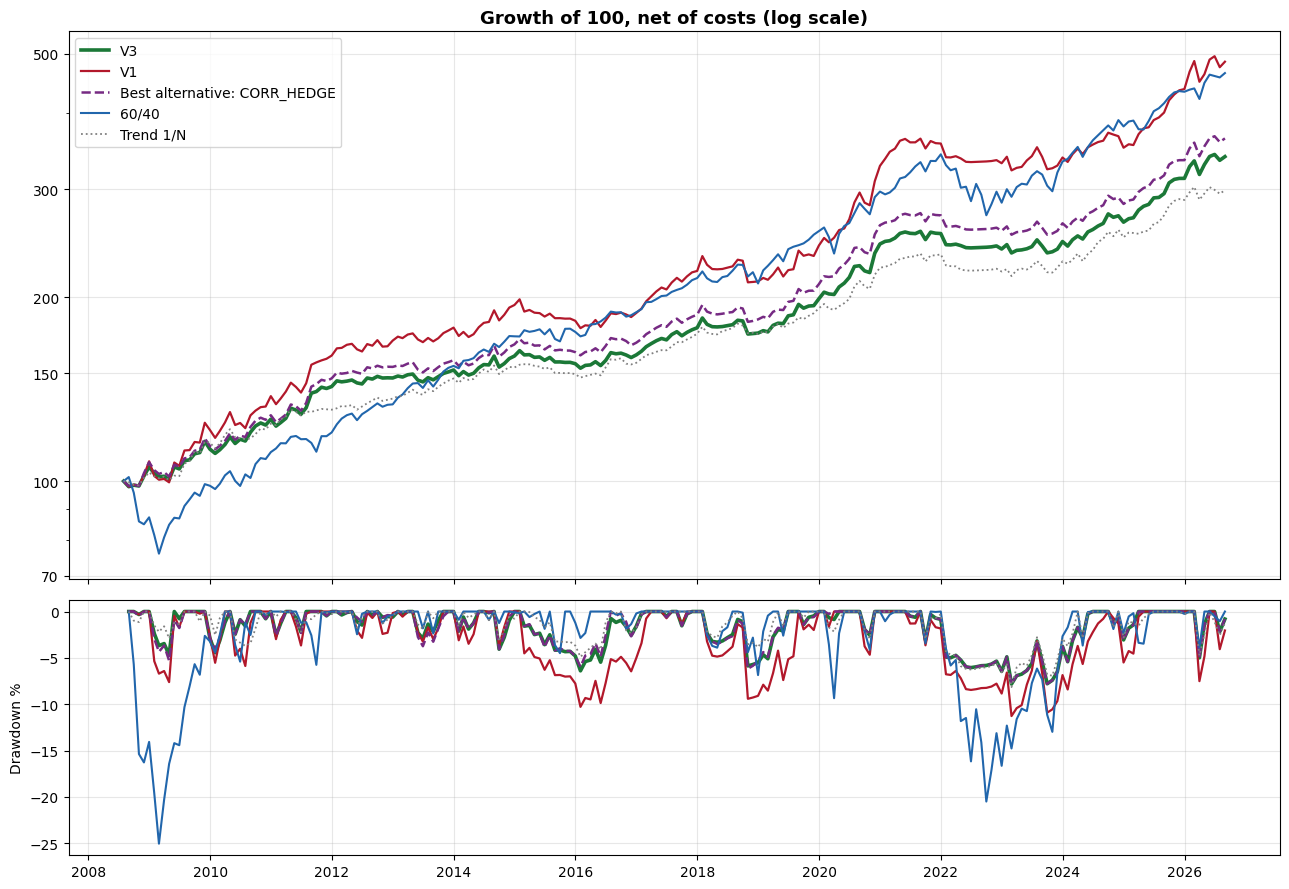

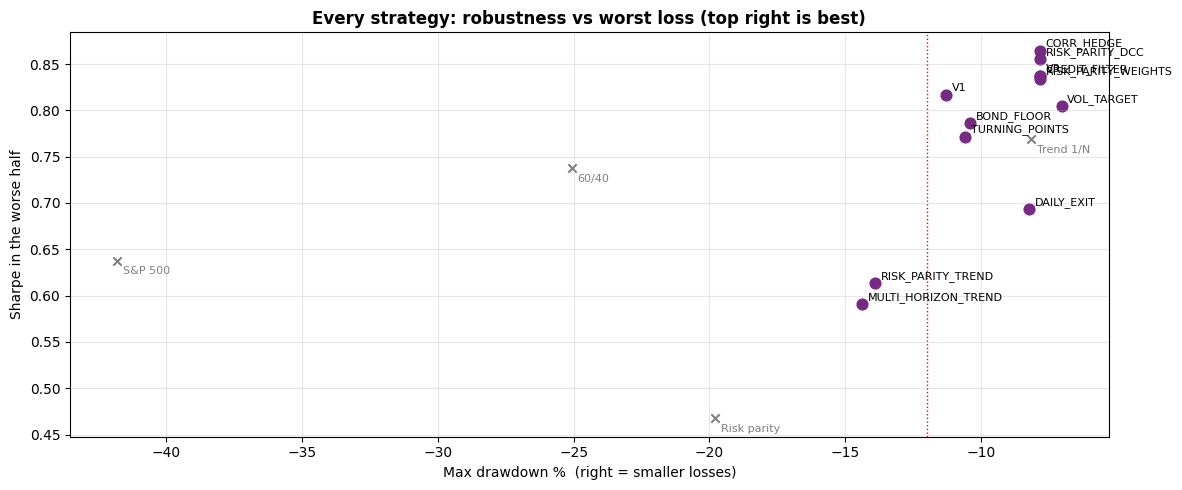

In [18]:
best_alt = [k for k in ranking.index if k not in ("V3", "V1")][0]
lines = [("V3", NET["V3"], dict(color="#1b7837", lw=2.6)), ("V1", NET["V1"], dict(color="#b2182b", lw=1.6)),
         (f"Best alternative: {best_alt}", NET[best_alt], dict(color="#762a83", lw=1.8, ls="--")),
         ("60/40", BENCH["60/40"], dict(color="#2166ac", lw=1.5)),
         ("Trend 1/N", BENCH["Trend 1/N"], dict(color="grey", lw=1.3, ls=":"))]
fig, (a1, a2) = plt.subplots(2, 1, figsize=(13, 9), gridspec_kw={"height_ratios": [3, 1.4]}, sharex=True)
for lab, r, st in lines:
    x = r.loc[idx]
    a1.plot(bm.equity_curve(x), label=lab, **st)
    nav = (1 + x).cumprod()
    a2.plot((nav / nav.cummax() - 1) * 100, **st)
bm._log_axis(a1)
a1.set_title("Growth of 100, net of costs (log scale)", fontsize=13, fontweight="bold")
a1.legend(loc="upper left"); a1.grid(alpha=0.3)
a2.set_ylabel("Drawdown %"); a2.grid(alpha=0.3)
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(12, 5))
cand = ranking
ax.scatter(cand["Max drawdown"] * 100, cand["Worse half"], s=60, color="#762a83")
for k, r in cand.iterrows():
    ax.annotate(k, (r["Max drawdown"] * 100, r["Worse half"]), fontsize=8, xytext=(4, 3), textcoords="offset points")
for k in BENCH:
    ax.scatter(res.loc[k, "Max drawdown"] * 100, res.loc[k, "Worse half"], marker="x", color="grey")
    ax.annotate(k, (res.loc[k, "Max drawdown"] * 100, res.loc[k, "Worse half"]), fontsize=8, color="grey",
                xytext=(4, -10), textcoords="offset points")
ax.axvline(MAX_DD_LIMIT * 100, color="red", ls=":", lw=1)
ax.set_xlabel("Max drawdown %  (right = smaller losses)"); ax.set_ylabel("Sharpe in the worse half")
ax.set_title("Every strategy: robustness vs worst loss (top right is best)", fontweight="bold")
ax.grid(alpha=0.3); plt.tight_layout(); plt.show()

## 8. Summary

In [19]:
v3, tr, b64 = res.loc["V3"], res.loc["Trend 1/N"], res.loc["60/40"]
print(f"Winner by the pre-set rule: {winner}.")
print(f"V3: Sharpe {v3['Sharpe']:.2f} (SE {v3['SE']:.2f}), {v3['Sharpe 2008-16']:.2f} and {v3['Sharpe 2017-26']:.2f} "
      f"in the two halves, max drawdown {v3['Max drawdown']:.1%}.")
print(f"60/40: Sharpe {b64['Sharpe']:.2f}, max drawdown {b64['Max drawdown']:.1%}. "
      f"Textbook trend: Sharpe {tr['Sharpe']:.2f}, max drawdown {tr['Max drawdown']:.1%}.")
sig = res.loc[ORDER[1:]]
sig = sig[sig["p vs v3"] < 0.10]
print("Alternatives with a Sharpe different from v3 beyond noise (p < 0.10): "
      + (", ".join(f"{k} ({'higher' if res.loc[k, 'Sharpe'] > v3['Sharpe'] else 'lower'}, {res.loc[k, 'Sharpe']:.2f})"
                   for k in sig.index) or "none") + ".")
print(f"Walk-forward vs v3 on {wf_idx[0]:%Y}-{wf_idx[-1]:%Y}: Sharpe {wf.loc['WALK_FORWARD', 'Sharpe']:.2f} vs "
      f"{wf.loc['V3', 'Sharpe']:.2f}.")
if tr["Worse half"] > v3["Worse half"] and tr["Max drawdown"] >= MAX_DD_LIMIT:
    print("Note: the textbook trend benchmark scores better than v3 on the same rule; v3 adds no value over it.")
else:
    print(f"Textbook trend benchmark: worse-half Sharpe {tr['Worse half']:.2f} vs v3 {v3['Worse half']:.2f}.")

Winner by the pre-set rule: V3.
V3: Sharpe 0.88 (SE 0.24), 0.93 and 0.84 in the two halves, max drawdown -7.8%.
60/40: Sharpe 0.79, max drawdown -25.1%. Textbook trend: Sharpe 0.88, max drawdown -8.2%.
Alternatives with a Sharpe different from v3 beyond noise (p < 0.10): DAILY_EXIT (lower, 0.77), BOND_FLOOR (lower, 0.84).
Walk-forward vs v3 on 2013-2026: Sharpe 0.68 vs 0.74.
Textbook trend benchmark: worse-half Sharpe 0.77 vs v3 0.84.
